**CS 4140 – Deep Learning · L15 · Sequences I: order and recurrent state** &nbsp; [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OWNER/4140-deep-learning/blob/main/lectures/L15_sequences-1/L15_sequences_recurrent_state.ipynb)

Run the first code cell before anything else. In Colab, *File → Save a copy in Drive* keeps your own changes.

In [ ]:
# ▶ Run this cell first. It gets the course code and this lecture's saved results and data,
#   in Google Colab or on your own computer.
LECTURE = "L15_sequences-1"
REPO = "https://github.com/OWNER/4140-deep-learning"
import os, sys, subprocess
root = os.path.abspath(os.path.join("..", ".."))
if not os.path.isfile(os.path.join(root, "cs4140_setup.py")):  # not inside the course repo (e.g. Colab)
    root = "/content/cs4140" if "google.colab" in sys.modules else os.path.abspath("cs4140")
    if not os.path.isdir(root):
        subprocess.run(["git", "clone", "--quiet", "--depth", "1", REPO, root], check=True)
    os.chdir(os.path.join(root, "lectures", LECTURE))
sys.path.insert(0, root)
import cs4140_setup
cs4140_setup.fetch_assets(LECTURE)

# CS 4140 · Lecture 15 · Sequences I: order and recurrent state
**Fri 26 Feb 2027 · demo notebook**

Can a network forecast tomorrow's temperature in Charlottetown? We compare two honest baselines, a dense network on a 14-day window, and a recurrent network that reads the 14 days one at a time.

**Before class:** run all cells once (about 30 seconds on a laptop CPU; nothing is downloaded). To skip training, set `TRAIN = False`: the saved weights in `saved/` give the same numbers.

| Section | What it shows |
|---|---|
| 1 | Charlottetown daily temperatures, 2013–2025 |
| 2 | Same numbers, different order |
| 3 | Windows and a split by time |
| 4 | Two baselines: persistence and climatology |
| 5 | A dense network on the window |
| 6 | `nn.RNN`: shapes, parameters, and the same numbers from a three-line loop |
| 7 | Results, and a cold snap |
| 8 | Inside the hidden state |
| 9 | Exercises |

Requires `torch`, `numpy`, `pandas`, `matplotlib`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

TRAIN = True      # False: load the saved weights instead of training (same results)
SEED = 4140
WINDOW = 14       # days of history each model sees
HIDDEN = 32       # hidden units in both networks

DATA, SAVED, FIGS = Path("data"), Path("saved"), Path("figures")
SAVED.mkdir(exist_ok=True)
FIGS.mkdir(exist_ok=True)

# Colours used on the slides: RNN orange, window network violet, data black, baselines grey
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
C_RNN, C_WIN, C_LSTM = "#eb6834", "#4a3aa7", "#2a78d6"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 13, "axes.titlesize": 14, "axes.labelsize": 13,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False,
})
print("PyTorch", torch.__version__)

PyTorch 2.14.1+cpu


## 1. Charlottetown temperatures

Daily mean temperature at **Charlottetown A** (the airport), from Environment and Climate Change Canada's historical climate data (climate ID 8300301, station 50621). The CSV in `data/` holds 13 years, 2013–2025. A few days are missing; we fill them by linear interpolation between the neighbouring days.

4,748 days, 2013-01-01 to 2025-12-31
missing days filled: 136 (2.9%)
coldest day: -22.1 °C on 2014-01-02
warmest day: 27.2 °C on 2025-08-12


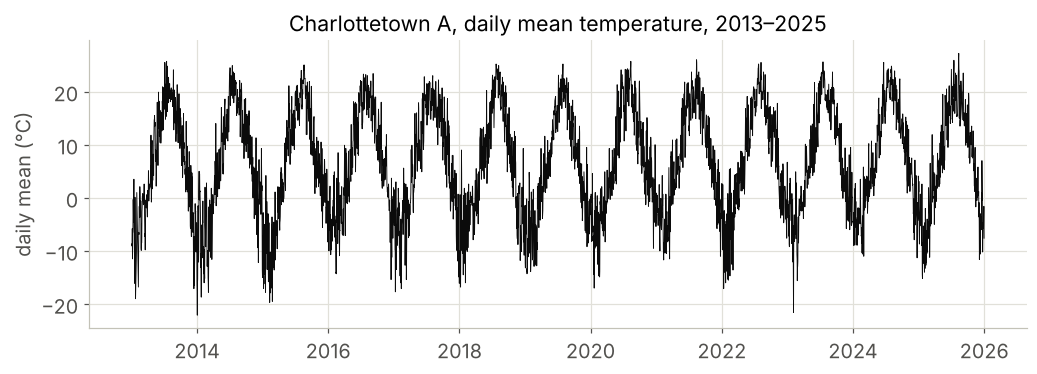

In [2]:
raw = pd.read_csv(DATA / "charlottetown_daily_2013_2025.csv", parse_dates=["date"], index_col="date")
missing = raw["mean_temp"].isna()
temp = raw["mean_temp"].interpolate()   # fill the missing days linearly

print(f"{len(temp):,} days, {temp.index[0].date()} to {temp.index[-1].date()}")
print(f"missing days filled: {missing.sum()} ({missing.mean():.1%})")
print(f"coldest day: {temp.min():.1f} °C on {temp.idxmin().date()}")
print(f"warmest day: {temp.max():.1f} °C on {temp.idxmax().date()}")

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(temp.index, temp.values, color=INK, lw=0.6)
ax.set_ylabel("daily mean (°C)")
ax.set_title("Charlottetown A, daily mean temperature, 2013–2025")
plt.show()

*Optional:* refresh or extend the data straight from Environment Canada (needs internet; one request per year).

In [3]:
REFRESH = False

def download_eccc(years, station_id=50621):
    url = ("https://climate.weather.gc.ca/climate_data/bulk_data_e.html?format=csv"
           "&stationID={}&Year={}&Month=1&Day=1&timeframe=2&submit=Download+Data")
    frames = [pd.read_csv(url.format(station_id, y), encoding="utf-8-sig") for y in years]
    df = pd.concat(frames, ignore_index=True)
    df["date"] = pd.to_datetime(df["Date/Time"])
    df = df.set_index("date").sort_index()
    return pd.DataFrame({"mean_temp": df["Mean Temp (°C)"], "max_temp": df["Max Temp (°C)"],
                         "min_temp": df["Min Temp (°C)"], "total_precip": df["Total Precip (mm)"]})

if REFRESH:
    fresh = download_eccc(range(2013, 2026))
    fresh.to_csv(DATA / "charlottetown_daily_2013_2025.csv", float_format="%.1f")

## 2. Same numbers, different order

The same 365 values, twice. On the left in calendar order; on the right shuffled. Mean, spread and histogram are identical. Only one can be forecast: **order is information.** A model that treats its input as a bag of numbers cannot tell them apart.

in order: mean 6.86 °C, std 9.99
shuffled: mean 6.86 °C, std 9.99


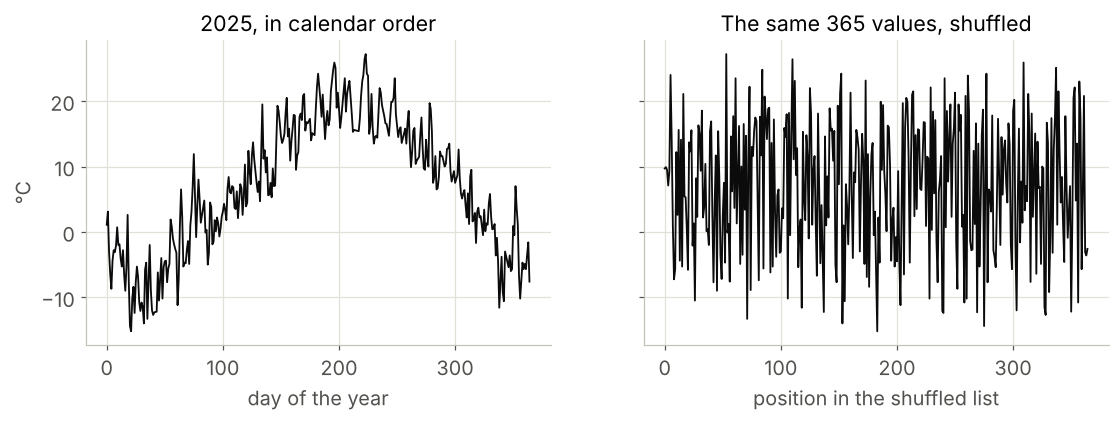

In [4]:
year = temp["2025"]
rng = np.random.default_rng(SEED)
shuffled = rng.permutation(year.values)
print(f"in order: mean {year.mean():.2f} °C, std {year.std(ddof=0):.2f}")
print(f"shuffled: mean {shuffled.mean():.2f} °C, std {shuffled.std():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
axes[0].plot(np.arange(365), year.values, color=INK, lw=1.2)
axes[0].set_title("2025, in calendar order")
axes[1].plot(np.arange(365), shuffled, color=INK, lw=1.2)
axes[1].set_title("The same 365 values, shuffled")
axes[0].set_xlabel("day of the year")
axes[1].set_xlabel("position in the shuffled list")
axes[0].set_ylabel("°C")
fig.savefig(FIGS / "l15_order_matters.png")
plt.show()

# the two panels as separate images, for the slides
ylim = axes[0].get_ylim()
for name, series, title, xlabel in [("in_order", year.values, "2025, in calendar order", "day of the year"),
                                    ("shuffled", shuffled, "The same 365 values, shuffled", "position in the shuffled list")]:
    f1, a1 = plt.subplots(figsize=(6, 3.6))
    a1.plot(np.arange(365), series, color=INK, lw=1.2)
    a1.set_ylim(ylim)
    a1.set_title(title)
    a1.set_xlabel(xlabel)
    a1.set_ylabel("°C")
    f1.savefig(FIGS / f"l15_order_{name}.png")
    plt.close(f1)

## 3. Windows and a split by time

**Windows.** Each training example is the last `WINDOW` days (the input) and the next day (the target). Sliding the window one day at a time turns 4,748 days into 4,734 examples.

**Split by time.** We train on the past and test on the future, as a real forecaster would:

* train: targets in 2013–2021
* validation (to choose the best epoch): 2022–2023
* test (touched once, at the end): 2024–2025

A window belongs to the set of its *target* day. We normalize with the mean and standard deviation of the **training days only**, so nothing from the future leaks into training.

training mean 6.26 °C, std 10.16 °C
X (4734, 14), y (4734,)
train 3,273 · validation 730 · test 731 windows


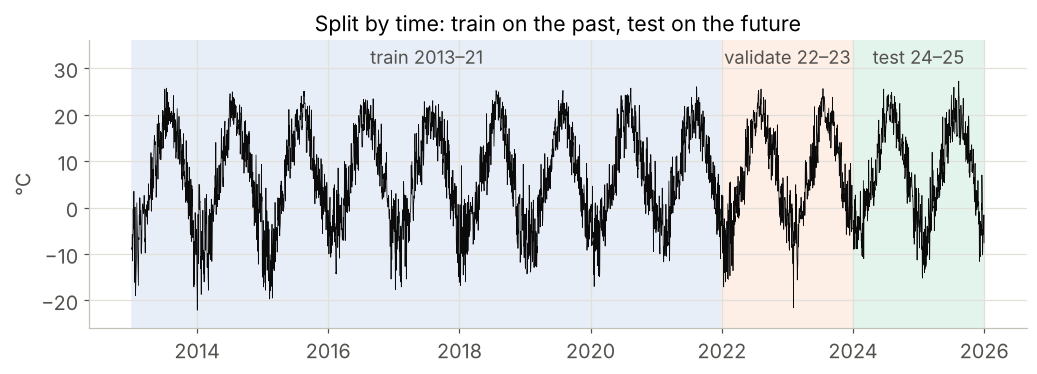

In [5]:
values = temp.values.astype(np.float32)
dates = temp.index
TRAIN_END, VAL_END = pd.Timestamp("2022-01-01"), pd.Timestamp("2024-01-01")

is_train_day = dates < TRAIN_END
MU, SD = values[is_train_day].mean(), values[is_train_day].std()
z = (values - MU) / SD                     # normalized series
print(f"training mean {MU:.2f} °C, std {SD:.2f} °C")

def make_windows(series, window):
    # X[i] holds days i .. i+window-1 ; y[i] is day i+window
    X = np.stack([series[t - window:t] for t in range(window, len(series))])
    y = series[window:]
    return X, y

X, y = make_windows(z, WINDOW)
target_dates = dates[WINDOW:]
idx_train = np.where(target_dates < TRAIN_END)[0]
idx_val = np.where((target_dates >= TRAIN_END) & (target_dates < VAL_END))[0]
idx_test = np.where(target_dates >= VAL_END)[0]
print(f"X {X.shape}, y {y.shape}")
print(f"train {len(idx_train):,} · validation {len(idx_val):,} · test {len(idx_test):,} windows")

def to_celsius(v):
    return v * SD + MU

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(dates, values, color=INK, lw=0.5)
for start, end, name, shade in [(dates[0], TRAIN_END, "train 2013–21", "#e8eef8"),
                                (TRAIN_END, VAL_END, "validate 22–23", "#fdeee6"),
                                (VAL_END, dates[-1], "test 24–25", "#e3f4ec")]:
    ax.axvspan(start, end, color=shade, zorder=0)
    ax.text(start + (end - start) / 2, 30, name, ha="center", va="bottom", color="#52514e", fontsize=12)
ax.set_ylim(-26, 36)
ax.set_ylabel("°C")
ax.set_title("Split by time: train on the past, test on the future")
fig.savefig(FIGS / "l15_split.png")
plt.show()

## 4. Two baselines

Any forecaster must beat the obvious ones:

* **Persistence:** tomorrow will be like today.
* **Climatology:** tomorrow will be the usual temperature for that date (the average for each calendar day over the training years, smoothed over a month).

We report the **mean absolute error (MAE) in °C** on the test years.

In [6]:
def mae_celsius(pred_z, true_z):
    return float(np.mean(np.abs(pred_z - true_z)) * SD)

# persistence: the last day of the window
persistence = X[:, -1]

# climatology: day-of-year average over the training years, smoothed with a 31-day circular window
doy = dates.dayofyear.values
table = pd.Series(values[is_train_day]).groupby(doy[is_train_day]).mean().reindex(range(1, 367)).interpolate()
padded = np.r_[table.values[-15:], table.values, table.values[:15]]
smooth = np.convolve(padded, np.ones(31) / 31, mode="same")[15:-15]
climatology = (smooth[doy - 1] - MU) / SD          # normalized, one value per day
climatology = climatology[WINDOW:]                 # aligned with the targets

results = {}
results["Climatology"] = mae_celsius(climatology[idx_test], y[idx_test])
results["Persistence"] = mae_celsius(persistence[idx_test], y[idx_test])
for name, v in results.items():
    print(f"{name:12s} test MAE {v:.2f} °C")

Climatology  test MAE 2.93 °C
Persistence  test MAE 2.48 °C


## 5. A dense network on the window

What we already know (15–18 Jan): flatten the 14 days into a vector and use a small dense network. One shared training function serves every model today: Adam, minibatches of 64, 40 epochs, and we keep the epoch with the best validation error.

In [7]:
Xt, yt = torch.tensor(X), torch.tensor(y)

class WindowNet(nn.Module):
    # 14 inputs -> 32 ReLU units -> 1 output
    def __init__(self, window=WINDOW, hidden=HIDDEN):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(window, hidden), nn.ReLU(), nn.Linear(hidden, 1))

    def forward(self, x):                  # x: (batch, window)
        return self.net(x).squeeze(-1)


def fit(model, epochs=40, lr=1e-3, batch_size=64, seed=SEED):
    gen = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    best_mae, best_state, best_epoch = float("inf"), None, -1
    for epoch in range(epochs):
        model.train()
        order = idx_train[torch.randperm(len(idx_train), generator=gen).numpy()]
        for i in range(0, len(order), batch_size):
            b = order[i:i + batch_size]
            opt.zero_grad()
            loss = loss_fn(model(Xt[b]), yt[b])
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            val_mae = mae_celsius(model(Xt[idx_val]).numpy(), y[idx_val])
        if val_mae < best_mae:
            best_mae, best_epoch = val_mae, epoch + 1
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    print(f"best validation MAE {best_mae:.2f} °C at epoch {best_epoch}")
    return model


def count_params(model):
    return sum(p.numel() for p in model.parameters())


torch.manual_seed(SEED)
window_net = WindowNet()
print("parameters:", count_params(window_net))
if TRAIN:
    fit(window_net)
    torch.save(window_net.state_dict(), SAVED / "l15_windownet.pt")
else:
    window_net.load_state_dict(torch.load(SAVED / "l15_windownet.pt"))

with torch.no_grad():
    pred_window = window_net(Xt).numpy()
results["Window network"] = mae_celsius(pred_window[idx_test], y[idx_test])
print(f"Window network test MAE {results['Window network']:.2f} °C")

parameters: 513


best validation MAE 2.47 °C at epoch 40
Window network test MAE 2.30 °C


## 6. A running summary, then the recurrent network

Before the RNN, a running summary we could design by hand: an exponential moving average,
$m_t = 0.8\,m_{t-1} + 0.2\,x_t$. One number, the same rule every day, and the whole past inside it with fading weights. (Momentum in SGD, 27 Jan, is the same recurrence applied to gradients.)

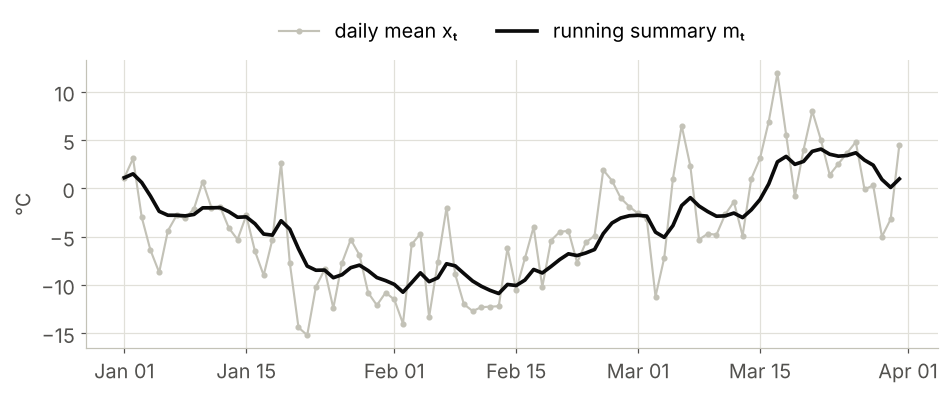

In [8]:
winter = temp["2025-01-01":"2025-03-31"]
m, ema = winter.iloc[0], []
for value in winter.values:
    m = 0.8 * m + 0.2 * value          # the update rule, chosen by hand
    ema.append(m)

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(winter.index, winter.values, color="#c3c2b7", lw=1.4, marker="o", ms=3, label="daily mean xₜ")
ax.plot(winter.index, ema, color=INK, lw=2.4, label="running summary mₜ")
import matplotlib.dates as mdates
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.set_ylabel("°C")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
fig.savefig(FIGS / "l15_running_average.png")
plt.show()

### The recurrent network

`nn.RNN` reads the window **one day at a time**, keeping a hidden state of 32 numbers:

$$h_t = \tanh(W_x x_t + W_h h_{t-1} + b), \qquad h_0 = 0,$$

and a linear layer turns the **last** hidden state into the forecast. The same $W_x$, $W_h$ and $b$ serve every step.

In [9]:
class RNNForecaster(nn.Module):
    def __init__(self, hidden=HIDDEN, layer=nn.RNN):
        super().__init__()
        self.rnn = layer(input_size=1, hidden_size=hidden, batch_first=True)
        self.head = nn.Linear(hidden, 1)

    def forward(self, x):                     # x: (batch, time)
        out, _ = self.rnn(x.unsqueeze(-1))    # (batch, time, 1) -> (batch, time, hidden)
        return self.head(out[:, -1]).squeeze(-1)   # forecast from the last hidden state


torch.manual_seed(SEED)
rnn_model = RNNForecaster()

# Shapes for one minibatch of 64 windows
xb = Xt[:64].unsqueeze(-1)                   # (batch, time, features)
out, h_n = rnn_model.rnn(xb)
print("input", tuple(xb.shape), "-> out", tuple(out.shape), " h_n", tuple(h_n.shape))

# Parameters: one set of weights for every step
for name, p in rnn_model.rnn.named_parameters():
    print(f"{name:13s} {str(tuple(p.shape)):9s} {p.numel():5d}")
print("nn.RNN total:", count_params(rnn_model.rnn), "· with the output layer:", count_params(rnn_model))

input (64, 14, 1) -> out (64, 14, 32)  h_n (1, 64, 32)
weight_ih_l0  (32, 1)      32
weight_hh_l0  (32, 32)   1024
bias_ih_l0    (32,)        32
bias_hh_l0    (32,)        32
nn.RNN total: 1120 · with the output layer: 1153


**No magic:** `nn.RNN` is this loop. PyTorch keeps two bias vectors, so $b$ = `bias_ih` + `bias_hh`.

In [10]:
W_x, W_h = rnn_model.rnn.weight_ih_l0, rnn_model.rnn.weight_hh_l0
b = rnn_model.rnn.bias_ih_l0 + rnn_model.rnn.bias_hh_l0

with torch.no_grad():
    h = torch.zeros(64, HIDDEN)
    for t in range(WINDOW):
        h = torch.tanh(xb[:, t] @ W_x.T + h @ W_h.T + b)
    print("largest difference from nn.RNN:", (h - out[:, -1]).abs().max().item())

# The same weights read any length: a whole year in one call
with torch.no_grad():
    year_in = torch.tensor(z[:365]).reshape(1, 365, 1)
    out_year, _ = rnn_model.rnn(year_in)
print("365 days in -> out", tuple(out_year.shape), "with the same", count_params(rnn_model.rnn), "parameters")

largest difference from nn.RNN: 8.940696716308594e-08
365 days in -> out (1, 365, 32) with the same 1120 parameters


## 7. Train, then compare on the test years

In [11]:
if TRAIN:
    fit(rnn_model)
    torch.save(rnn_model.state_dict(), SAVED / "l15_rnn.pt")
else:
    rnn_model.load_state_dict(torch.load(SAVED / "l15_rnn.pt"))

with torch.no_grad():
    pred_rnn = rnn_model(Xt).numpy()
results["RNN"] = mae_celsius(pred_rnn[idx_test], y[idx_test])

params = {"Climatology": "—", "Persistence": "—",
          "Window network": count_params(window_net), "RNN": count_params(rnn_model)}
print(f"{'model':16s}{'test MAE (°C)':>14s}{'parameters':>12s}")
for name, v in results.items():
    print(f"{name:16s}{v:14.2f}{str(params[name]):>12s}")

best validation MAE 2.46 °C at epoch 13
model            test MAE (°C)  parameters
Climatology               2.93           —
Persistence               2.48           —
Window network            2.30         513
RNN                       2.29        1153


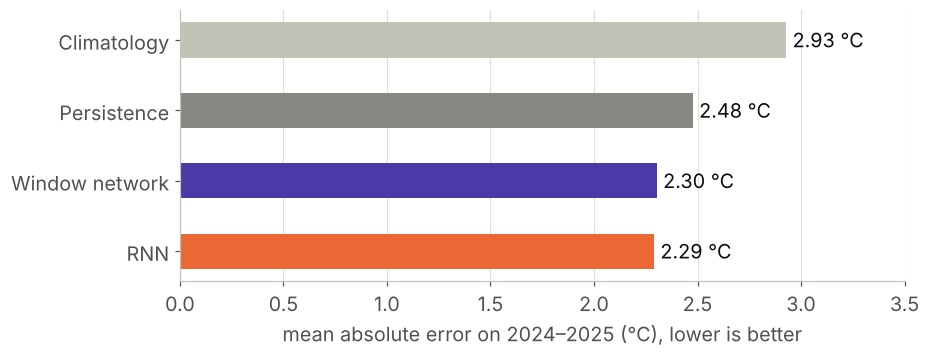

In [12]:
# Slide figure: test MAE, lower is better
names = ["Climatology", "Persistence", "Window network", "RNN"]
colours = ["#c3c2b7", "#898781", C_WIN, C_RNN]
fig, ax = plt.subplots(figsize=(8.5, 3.2))
ax.set_axisbelow(True)
bars = ax.barh(names[::-1], [results[n] for n in names[::-1]], color=colours[::-1], height=0.5)
for bar, n in zip(bars, names[::-1]):
    ax.text(bar.get_width() + 0.03, bar.get_y() + bar.get_height() / 2, f"{results[n]:.2f} °C",
            va="center", color=INK, fontsize=13)
ax.set_xlim(0, 3.5)
ax.set_xlabel("mean absolute error on 2024–2025 (°C), lower is better")
ax.grid(axis="y", visible=False)
fig.savefig(FIGS / "l15_results.png")
plt.show()

**A cold snap.** Persistence is always one day late: it repeats today. The RNN has learned something about how temperatures move, for instance that extremes tend to ease back towards the seasonal normal.

2025-01-12 to 2025-02-09: persistence MAE 3.79 °C, RNN MAE 3.18 °C

          actual  persistence    RNN
Jan 19       2.6         -5.3   -4.2
Jan 20      -7.7          2.6    0.5
Jan 21     -14.4         -7.7   -8.8
Jan 22     -15.2        -14.4   -9.4
Jan 23     -10.2        -15.2  -10.6
Jan 24      -8.4        -10.2   -7.7


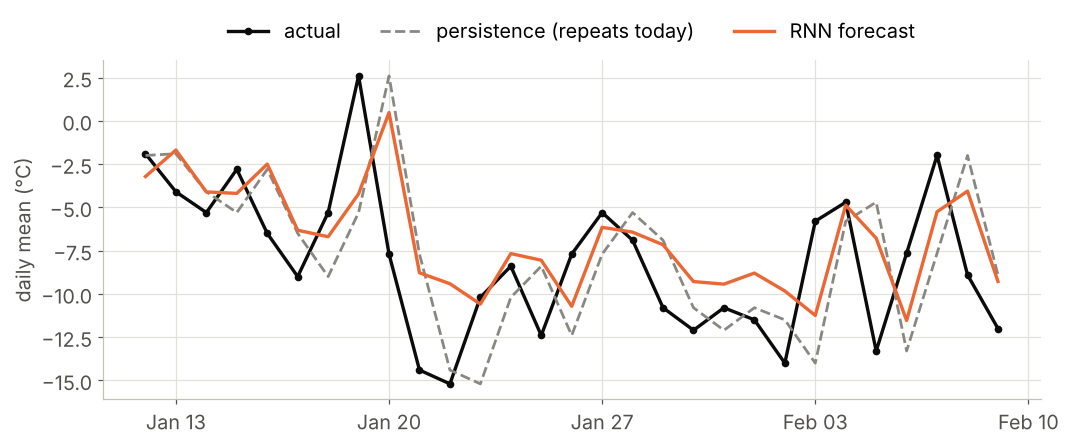

In [13]:
test_dates = target_dates[idx_test]
start, end = pd.Timestamp("2025-01-12"), pd.Timestamp("2025-02-09")
sel = (test_dates >= start) & (test_dates <= end)
d = test_dates[sel]
actual_c = to_celsius(y[idx_test][sel])
pers_c = to_celsius(persistence[idx_test][sel])
rnn_c = to_celsius(pred_rnn[idx_test][sel])
print(f"{start.date()} to {end.date()}: persistence MAE {np.mean(np.abs(pers_c - actual_c)):.2f} °C, "
      f"RNN MAE {np.mean(np.abs(rnn_c - actual_c)):.2f} °C")
print("\n          actual  persistence    RNN")
for dd, a, p, r in zip(d, actual_c, pers_c, rnn_c):
    if pd.Timestamp("2025-01-19") <= dd <= pd.Timestamp("2025-01-24"):
        print(f"{dd:%b %d}   {a:7.1f}  {p:11.1f}  {r:5.1f}")

import matplotlib.dates as mdates
fig, ax = plt.subplots(figsize=(11, 4.0))
ax.plot(d, actual_c, color=INK, lw=2.2, marker="o", ms=4, label="actual")
ax.plot(d, pers_c, color=MUTED, lw=1.8, ls="--", label="persistence (repeats today)")
ax.plot(d, rnn_c, color=C_RNN, lw=2.2, label="RNN forecast")
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.set_ylabel("daily mean (°C)")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3)
fig.savefig(FIGS / "l15_cold_snap.png")
plt.show()

## 8. Inside the hidden state

The hidden state is a running summary: 32 numbers, updated once per day. Below, the 14 inputs of one test window (top) and the 32 hidden units at each step (bottom, red = positive, blue = negative). The forecast is read from the last column.

window 2025-01-09 to 2025-01-22; forecast for 2025-01-23: -10.6 °C, actual -10.2 °C, persistence -15.2 °C


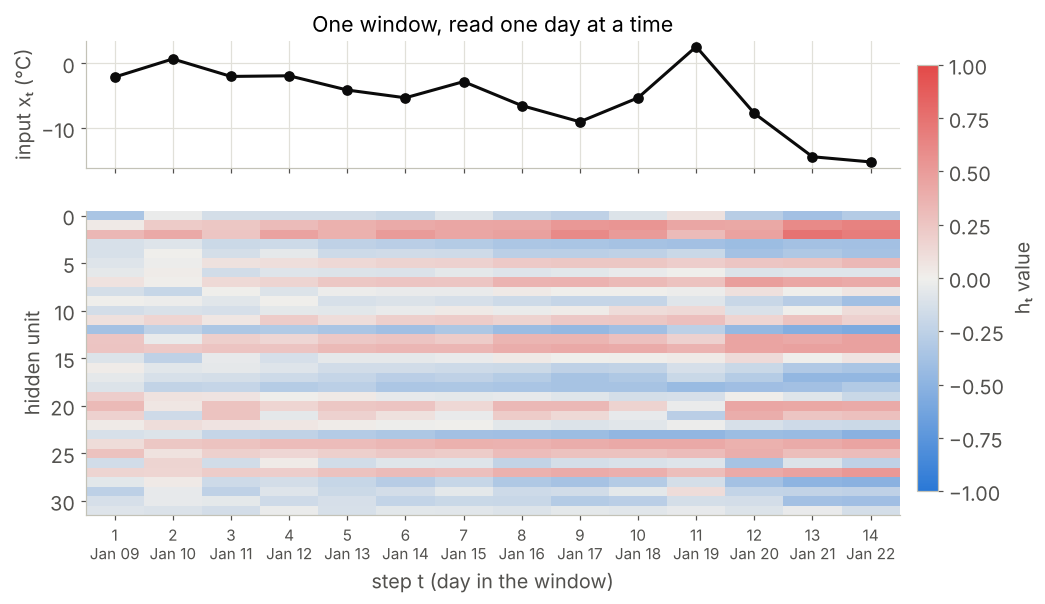

In [14]:
# one window to look inside (try other days): the 14 days before 23 Jan 2025
EXAMPLE_DAY = pd.Timestamp("2025-01-23")
example = int(np.where(target_dates == EXAMPLE_DAY)[0][0])
x_win = Xt[example:example + 1]
with torch.no_grad():
    states, _ = rnn_model.rnn(x_win.unsqueeze(-1))
    forecast = to_celsius(rnn_model(x_win).item())
states = states[0].numpy().T                  # (hidden, time)
days = pd.date_range(end=EXAMPLE_DAY - pd.Timedelta(days=1), periods=WINDOW)
print(f"window {days[0].date()} to {days[-1].date()}; forecast for {EXAMPLE_DAY.date()}: "
      f"{forecast:.1f} °C, actual {to_celsius(y[example]):.1f} °C, persistence {to_celsius(X[example, -1]):.1f} °C")

from matplotlib.colors import LinearSegmentedColormap
diverging = LinearSegmentedColormap.from_list("blue_grey_red", ["#2a78d6", "#f0efec", "#e34948"])

fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(10, 5.6), sharex=True,
                               gridspec_kw={"height_ratios": [1, 2.4]})
ax0.plot(range(WINDOW), to_celsius(X[example]), "o-", color=INK, lw=2, ms=6)
ax0.set_ylabel("input xₜ (°C)")
ax0.set_title("One window, read one day at a time")
im = ax1.imshow(states, aspect="auto", cmap=diverging, vmin=-1, vmax=1, interpolation="nearest")
ax1.set_ylabel("hidden unit")
ax1.set_xlabel("step t (day in the window)")
ax1.set_xticks(range(WINDOW))
ax1.set_xticklabels([f"{t + 1}\n{dd:%b %d}" for t, dd in enumerate(days)], fontsize=10)
ax1.grid(False)
cbar = fig.colorbar(im, ax=[ax0, ax1], fraction=0.025, pad=0.02)
cbar.set_label("hₜ value")
fig.savefig(FIGS / "l15_hidden_state.png")
plt.show()

## 9. Exercises

1. **Window length.** Change `WINDOW` to 7, 30 and 60. Do the RNN and the window network still tie? Why might they?
2. **Width.** Try `HIDDEN = 8` and `HIDDEN = 64` for the RNN. Count the parameters. Does the test error move?
3. **More inputs.** Feed the daily maximum and minimum as well (`input_size=3`). Which shapes change in the code?
4. **Leakage.** Replace the split by time with a random split of the windows. What happens to the test error, and why is that number misleading?
5. **Further ahead.** Forecast the day after tomorrow. How do persistence and climatology compare now?